# HO-Brent crack APO: pricing walkthrough

A call on the June 2027 average of the **NY Harbor ULSD - ICE Brent** crack, strike 32 $/bbl,
25 000 bbl, valued on 10 Nov 2026. Illustrative terms; it is trade APO-003 of
`portfolios/example_book.yaml`.

> **Market snapshot as of 10 Nov 2026**, frozen so the numbers are reproducible (they match the README and the tests): NYMEX ULSD Jul-27 at 2.50 $/gal, ICE Brent Aug-27 at 75 $/bbl, ATM option prices for the implied vols, correlation 0.95, USD rate 4%. For live forwards, see notebook 02.

1. Market data: futures and implied vols from listed options
2. The trade: contract terms and averaging schedule
3. Price with three models (Bachelier, Kirk, Monte Carlo)
4. Deltas and futures hedge
5. Sensitivity to the crack level and to correlation

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import QuantLib as ql

from cmdty import (GAL_PER_BBL, AveragingSchedule, Leg, MarketData, Pricer, Quote,
                   APO, ice_futures_europe_calendar, implied_vol_black76,
                   joint_calendar, nymex_calendar)
from cmdty.plotting import (SERIES, area_line, last_value, price_axis_right, ref_line,
                            ref_vline, titles, use_style)

use_style()
COLORS = {"bachelier": SERIES[0], "kirk": SERIES[1], "mc": SERIES[2]}

## 1. Market data

ULSD is quoted in $$$/gal on NYMEX, so it is converted to $/bbl (x 42). Vols are implied from
ATM listed options by inverting Black-76; correlation is an input (estimated from history in
the Yahoo notebook).

In [2]:
today = ql.Date(10, 11, 2026)
F_HO = 2.50 * GAL_PER_BBL   # NYMEX ULSD Jul-27, $/gal -> $/bbl
F_BR = 75.0                 # ICE Brent Aug-27

t_opt = ql.Actual365Fixed().yearFraction(today, ql.Date(30, 6, 2027))
vol_ho = implied_vol_black76(0.238 * GAL_PER_BBL, F_HO, F_HO, t_opt)   # ATM premium, $/gal
vol_br = implied_vol_black76(7.61, F_BR, F_BR, t_opt)                  # ATM premium, $/bbl

market = MarketData(
    today=today,
    rate=0.04,
    quotes={"HO": Quote(F_HO, vol_ho), "BRENT": Quote(F_BR, vol_br)},
    correlations={("HO", "BRENT"): 0.95},
)
pd.DataFrame({"forward $/bbl": [F_HO, F_BR], "implied vol": [vol_ho, vol_br]},
             index=["HO", "BRENT"]).round(4)

,forward $/bbl,implied vol
HO,105.0,0.3000
BRENT,75.0,0.3199


## 2. The trade

Contract terms only, no prices. The averaging schedule uses the **common** NYMEX/ICE days
(ISDA *Common Pricing*): 18 June (Juneteenth) is excluded because NYMEX is closed, even though
ICE Brent settles that day.

In [3]:
apo = APO(
    legs=[Leg("HO", 1), Leg("BRENT", -1)],
    strike=32.0,
    quantity=25_000,
    schedule=AveragingSchedule(
        pricing_period="2027-06",
        calendar=joint_calendar(nymex_calendar(), ice_futures_europe_calendar()),
        pay_lag=5,  # paid 8 Jul 2027 (5 Jul is the US holiday)
    ),
)
fixings = apo.schedule.fixing_dates()
print(f"fixings : {len(fixings)} days, {fixings[0].ISO()} -> {fixings[-1].ISO()}")
print(f"pay date: {apo.schedule.pay_date.ISO()}")
print(f"T_eff   : {apo.schedule.t_eff(today):.4f} years")

fixings : 21 days, 2027-06-01 -> 2027-06-30
pay date: 2027-07-08
T_eff   : 0.5807 years


## 3. Price with three models

- **Bachelier**: the crack is normal, its $ vol is built from the legs.
- **Kirk**: two lognormal legs, `ql.KirkEngine` with maturity T_eff.
- **Monte Carlo**: two correlated futures simulated on the 21 actual fixings.

In [4]:
pricer = Pricer(model="kirk", market=market)
rows = {}
for model in ("bachelier", "kirk", "mc"):
    p = pricer.with_model(model)
    pv = p.pv(apo)
    rows[model] = {"payoff $/bbl": p.expected_payoff(apo), "PV $/bbl": pv,
                   "PV trade $": pv * apo.quantity}
results = pd.DataFrame(rows).T
results.round({"payoff $/bbl": 3, "PV $/bbl": 3, "PV trade $": 0})

,payoff $/bbl,PV $/bbl,PV trade $
bachelier,2.584,2.517,62913.0
kirk,2.686,2.617,65419.0
mc,2.667,2.598,64941.0


Kirk is about 0.02 $/bbl above the Monte Carlo: the T_eff shortcut is a small approximation.
The gap with Bachelier (about 2 500 $ on the trade) is model risk: normal vs lognormal view of
the crack.

## 3b. Discounting depends on the trade

The curve comes from the market (4% flat here). Which date is read on it, and whether it is
read at all, comes from the contract: the pay date and the premium style. Same trade, same
market, three payment terms:

In [5]:
variants = {
    "upfront, paid 8 Jul (lag 5)": apo,
    "upfront, paid 30 bd after": apo.model_copy(update={"schedule": apo.schedule.model_copy(update={"pay_lag": 30})}),
    "futures-style margined": apo.model_copy(update={"premium_style": "futures_style"}),
}
rows = {}
for label, trade in variants.items():
    df = pricer.discount_factor(trade)
    pv = pricer.pv(trade)
    rows[label] = {"pay date": trade.schedule.pay_date.ISO(), "DF": df, "PV $/bbl": pv,
                   "PV trade $": pv * trade.quantity}
table = pd.DataFrame(rows).T
table = table.astype({"DF": float, "PV $/bbl": float, "PV trade $": float})
table.round({"DF": 4, "PV $/bbl": 3, "PV trade $": 0})

,pay date,DF,PV $/bbl,PV trade $
"upfront, paid 8 Jul (lag 5)",2027-07-08,0.9740,2.617,65419.0
"upfront, paid 30 bd after",2027-08-12,0.9703,2.607,65168.0
futures-style margined,2027-07-08,1.0000,2.686,67162.0


Kirk, same expected payoff (2.686 $/bbl) in every row: only the discount factor moves.
Margined daily, the trade is worth about 1 700 $ more than paid upfront. Over 8 months at 4% the
effect is visible, on a longer trade or a large book it matters more.

## 4. Greeks

All sensitivities bump the **market** snapshot and reprice the same trade (per bbl):

| Greek | Bump |
|---|---|
| delta HO / Brent | +1 $ on one leg |
| delta crack | HO +0.5 $, Brent -0.5 $ |
| delta outright | both legs +1 $ together (flat price risk) |
| gamma | change of delta per $ |
| vega | +1 vol point on one leg |
| corr | +0.01 correlation |
| theta | one calendar day, same market |
| rho | +1 bp on the discount rate |

In [6]:
rows = {m: pricer.with_model(m).greeks(apo).to_dict() for m in ("bachelier", "kirk", "mc")}
greeks = pd.DataFrame(rows).T
greeks.round(4)

,pv,delta_leg1,delta_leg2,delta_crack,delta_outright,gamma_leg1,gamma_leg2,gamma_crack,vega_leg1,vega_leg2,corr_sens,theta,rho
bachelier,2.5165,0.3991,-0.3991,0.3991,0.0000,0.0432,0.0432,0.0432,0.2293,-0.1116,-0.1901,-0.0076,-0.0002
kirk,2.6167,0.4178,-0.4005,0.4091,0.0174,0.0428,0.0422,0.0425,0.2380,-0.1166,-0.1846,-0.0078,-0.0002
mc,2.5976,0.4242,-0.4063,0.4152,0.0179,0.0434,0.0431,0.0432,0.2329,-0.1121,-0.1896,-0.0078,-0.0002


In [7]:
g = greeks.loc["kirk"]
lot = 1_000  # bbl per NYMEX HO / ICE Brent lot
print(f"crack hedge   : {g.delta_crack * apo.quantity / lot:+.2f} lots of crack")
print(f"outright      : {g.delta_outright * apo.quantity:+,.0f} bbl of flat price risk left")
print(f"theta per day : {g.theta * apo.quantity:+,.0f} $")
print(f"vega HO       : {g.vega_leg1 * apo.quantity:+,.0f} $ per vol point")

crack hedge   : +10.23 lots of crack
outright      : +434 bbl of flat price risk left
theta per day : -195 $
vega HO       : +5,951 $ per vol point


Reading the table:

- **Bachelier** only sees the spread: delta outright is zero, all gammas are equal.
- **Lognormal models** leave a small **outright** residual (~ +0.017, about 430 bbl on 25 000).
- **Vega Brent is negative**: crack variance is σ_HO² + σ_BR² - 2ρ σ_HO σ_BR. With ρ = 0.95,
  more Brent vol means *less* crack vol.
- **Correlation** is the largest model-risk input: -0.18 $/bbl per +0.01.

## 5. Sensitivities

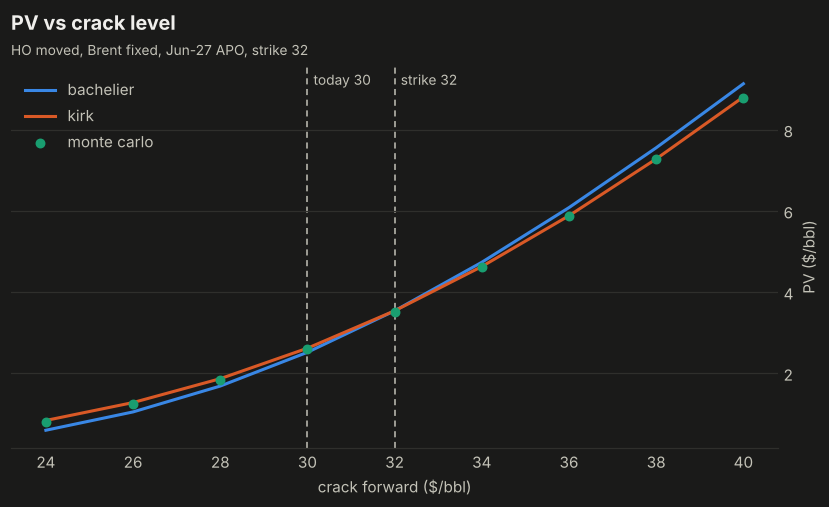

In [8]:
crack = np.linspace(24, 40, 9)   # move HO, keep Brent
fig, ax = plt.subplots(figsize=(9, 4.5))
for model in ("bachelier", "kirk", "mc"):
    p = pricer.with_model(model)
    if model == "mc":
        p = p.with_model_kwargs(n_paths=50_000)
    pv = [p.with_market(market.bump_forward("HO", c - (F_HO - F_BR))).pv(apo) for c in crack]
    if model == "mc":
        ax.scatter(crack, pv, color=COLORS[model], s=30, zorder=4, label="monte carlo")
    else:
        ax.plot(crack, pv, color=COLORS[model], label=model)
ref_vline(ax, apo.strike, "strike 32")
ref_vline(ax, F_HO - F_BR, "today 30")
price_axis_right(ax)
ax.set(xlabel="crack forward ($/bbl)", ylabel="PV ($/bbl)")
titles(ax, "PV vs crack level", "HO moved, Brent fixed, Jun-27 APO, strike 32")
ax.legend(loc="upper left")
plt.show()

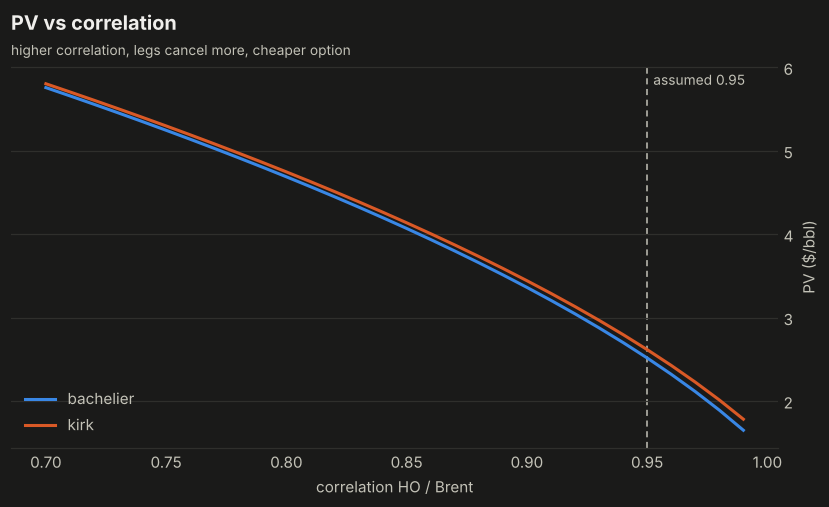

In [9]:
rhos = np.linspace(0.70, 0.99, 30)
fig, ax = plt.subplots(figsize=(9, 4.5))
for model in ("bachelier", "kirk"):
    pv = [pricer.with_model(model).with_market(
              market.model_copy(update={"correlations": {("HO", "BRENT"): r}})).pv(apo)
          for r in rhos]
    ax.plot(rhos, pv, color=COLORS[model], label=model)
ref_vline(ax, 0.95, "assumed 0.95")
price_axis_right(ax)
ax.set(xlabel="correlation HO / Brent", ylabel="PV ($/bbl)")
titles(ax, "PV vs correlation", "higher correlation, legs cancel more, cheaper option")
ax.legend(loc="lower left")
plt.show()

Higher correlation means the legs cancel more, a lower crack vol and a cheaper option.
Correlation has no liquid market, so this curve is a key model-risk input.